# **Clasificación de la forma reportada en avistamientos de OVNIS en Estados Unidos mediante aprendizaje automático**

**Alumno:** Ariel Tuñon  
---

# DATOS LIMPIOS Y PREPARADOS - CARGA DE LIBRERIAS Y DATASET

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore')
import cufflinks as cf
import plotly.offline
cf.go_offline()
cf.set_config_file(offline=False, world_readable=True)

# URL en formato raw corregida (cambiando 'blob' por 'raw')
url_csv = "https://github.com/arieltunon74/Aprendizaje_automatico_parcial_2026/raw/main/data/processed/dataset_procesado.csv"

print("Cargando el dataset procesado desde GitHub...")
# Especificamos sep=';' ya que el archivo utiliza punto y coma como delimitador
df_procesado = pd.read_csv(url_csv, sep=';')

print("\n¡Dataset procesado cargado exitosamente!")
print(f"Total de registros (filas): {df_procesado.shape[0]:,}")
print(f"Total de columnas: {df_procesado.shape[1]}")

Cargando el dataset procesado desde GitHub...

¡Dataset procesado cargado exitosamente!
Total de registros (filas): 79,695
Total de columnas: 25



#ANÁLISIS EXPLORATORIO DE DATOS (EDA)

##Inspección de filas, columnas, tipos de datos y estadísticas

---

###Procedimientos de inspección

1. Visualización de registros iniciales y finales.
2. Análisis y exploración de la variable objetivo y las demás variables
2. Consulta de las dimensiones del DataFrame.
3. Revisión de nombres y tipos de columnas.
4. Obtención de estadísticas descriptivas.
5. Identificación de valores faltantes y duplicados.
6. Visualizaciones y analisis varios.

---


---

Las columnas id, summary Y details_url -- NO APARECEN PORQUE NO SE TENDRÁN EN CUENTA EN EL MODELO

---



## 1. Visualización de registros iniciales y finales

### Primeras 10 filas del dataset

In [2]:
# Ver las primeras 10 filas del dataset
print("\n--- Primeras filas del dataset (.head()) ---")
display(df_procesado.head(10))




--- Primeras filas del dataset (.head()) ---


,occurred_date_time,city,state,shape,duration,posted_date,year,state_grouped,duration_seconds,occurred_datetime,...,Duracion_clasificacion,hour,time_of_day,is_weekend,shape_grouped,decade,us_region,posted_year,posted_month,posted_dayofweek
0,7/12/19 09:20,Redding,CA,Cylinder,5 minutes,2019-07-12,2019,CA,300,2019-07-12 09:20:00,...,Corto,9,Mañana,Día de semana,Other,2010s,West,2019,7,Friday
1,7/12/19 03:30,Charlotte,NC,Other,20 minutes,2019-07-12,2019,Other,1200,2019-07-12 03:30:00,...,Medio,3,Madrugada,Día de semana,Other,2010s,South,2019,7,Friday
2,7/11/19 22:40,Cedar Creek,TX,Other,20 seconds,2019-07-12,2019,TX,20,2019-07-11 22:40:00,...,Muy corto,22,Noche,Día de semana,Other,2010s,South,2019,7,Friday
3,7/11/19 22:10,San Bernardino,CA,Triangle,2 minutes,2019-07-12,2019,CA,120,2019-07-11 22:10:00,...,Corto,22,Noche,Día de semana,Triangle,2010s,West,2019,7,Friday
4,7/11/19 22:00,Bowling Green,KY,Other,45 minutes,2019-07-12,2019,Other,2700,2019-07-11 22:00:00,...,Largo,22,Noche,Día de semana,Other,2010s,South,2019,7,Friday
5,7/11/19 21:30,Dayton,NV,Circle,2 minutes,2019-07-12,2019,Other,120,2019-07-11 21:30:00,...,Corto,21,Noche,Día de semana,Circle,2010s,West,2019,7,Friday
6,7/11/19 20:25,Lakeland/Nashville border,GA,Changing,2 minutes,2019-07-12,2019,Other,120,2019-07-11 20:25:00,...,Corto,20,Noche,Día de semana,Other,2010s,South,2019,7,Friday
7,7/11/19 19:30,Pleasanton,CA,Light,5 minutes,2019-07-12,2019,CA,300,2019-07-11 19:30:00,...,Corto,19,Noche,Día de semana,Light,2010s,West,2019,7,Friday
8,7/11/19 05:15,Boise,ID,Circle,5 seconds,2019-07-12,2019,Other,5,2019-07-11 05:15:00,...,Muy corto,5,Madrugada,Día de semana,Circle,2010s,West,2019,7,Friday
9,7/11/19 02:50,Franklin-Alvadore,OR,Light,60 seconds,2019-07-12,2019,Other,60,2019-07-11 02:50:00,...,Muy corto,2,Madrugada,Día de semana,Light,2010s,West,2019,7,Friday


### Últimas 10 filas del dataset

In [3]:
# Ver las últimas 10 filas del dataset
print("\n--- Últimas filas del dataset (.tail()) ---")
display(df_procesado.tail(10))


--- Últimas filas del dataset (.tail()) ---


,occurred_date_time,city,state,shape,duration,posted_date,year,state_grouped,duration_seconds,occurred_datetime,...,Duracion_clasificacion,hour,time_of_day,is_weekend,shape_grouped,decade,us_region,posted_year,posted_month,posted_dayofweek
79685,8/24/00 22:14,Adams,NY,Light,1 hour,2000-09-17,2000,NY,3600,2000-08-24 22:14:00,...,Largo,22,Noche,Día de semana,Light,2000s,Northeast,2000,9,Sunday
79686,1970 22:00,Raymond,MS,Disk,30 min.,2001-10-12,1970,Other,1800,1970-01-01 22:00:00,...,Medio,22,Noche,Día de semana,Disk,1970s,South,2001,10,Friday
79687,06/24/2000 22:00,Hurricane,WV,Formation,30 seconds,2001-08-05,2000,Other,30,2000-06-24 22:00:00,...,Muy corto,22,Noche,Fin de semana,Other,2000s,South,2001,8,Sunday
79688,09/11/01 20:45,Griffin,GA,Disk,15 seconds,2001-10-12,2001,Other,15,2001-09-11 20:45:00,...,Muy corto,20,Noche,Día de semana,Disk,2000s,South,2001,10,Friday
79689,1962 20:00,Roseville,MI,Triangle,2 minutes,1999-10-19,1962,Other,120,1962-01-01 20:00:00,...,Corto,20,Noche,Día de semana,Triangle,1960s,Midwest,1999,10,Tuesday
79690,10/27/01 18:00,Roseville,CA,Chevron,1/2 hour,2001-11-20,2001,CA,3600,2001-10-27 18:00:00,...,Largo,18,Tarde,Fin de semana,Other,2000s,West,2001,11,Tuesday
79691,April '99 15:00,University Heights,OH,Cigar,26 seconds,1999-05-24,1999,OH,26,1999-04-01 15:00:00,...,Muy corto,15,Tarde,Día de semana,Other,1990s,Midwest,1999,5,Monday
79692,12/24/98 06:24,Bartlett,IL,Cigar,25 secs.,1999-02-16,1998,IL,25,1998-12-24 06:24:00,...,Muy corto,6,Mañana,Día de semana,Other,1990s,Midwest,1999,2,Tuesday
79693,07/11/99 04:30,New York City (Bronx),NY,Light,1.5 min.,1999-07-14,1999,NY,90,1999-07-11 04:30:00,...,Corto,4,Madrugada,Fin de semana,Light,1990s,Northeast,1999,7,Wednesday
79694,08--87 01:00,Fort Carson,CO,Light,5-min,2000-09-17,1987,Other,300,1987-08-01 01:00:00,...,Muy corto,1,Madrugada,Fin de semana,Light,1980s,West,2000,9,Sunday


## 2. Análisis y exploración de la variable objetivo y las demás variables

2.1. ANÁLISIS DE CLASES DE LA VARIABLE PREDICTORA `shape`

(FORMA DEL OVNI / UFO / UAP EN TODO EL MUNDO)

---

##Exploración de la variable objetivo y otras


========== VARIABLE OBJETIVO: SHAPE ==========

Cantidad de variables del dataset: 25
Cantidad de clases de Shape: 28

Formas de OVNI registradas:
['Cylinder' 'Other' 'Triangle' 'Circle' 'Changing' 'Light' 'Sphere'
 'Cigar' 'Fireball' 'Oval' 'Flash' 'Rectangle' 'Formation' 'Disk' 'Egg'
 'Teardrop' 'Chevron' 'Diamond' 'Cross' 'Cone' 'Hexagon' 'Flare'
 'Crescent' 'Delta' 'diamond' 'pyramid' 'Round' 'Dome']

Cantidad de frecuencia de registros por forma:


,Cantidad de registros
shape,
Light,18564
Circle,9081
Triangle,8562
Fireball,7177
Sphere,5992
Other,5894
Disk,4433
Oval,3801
Formation,2921


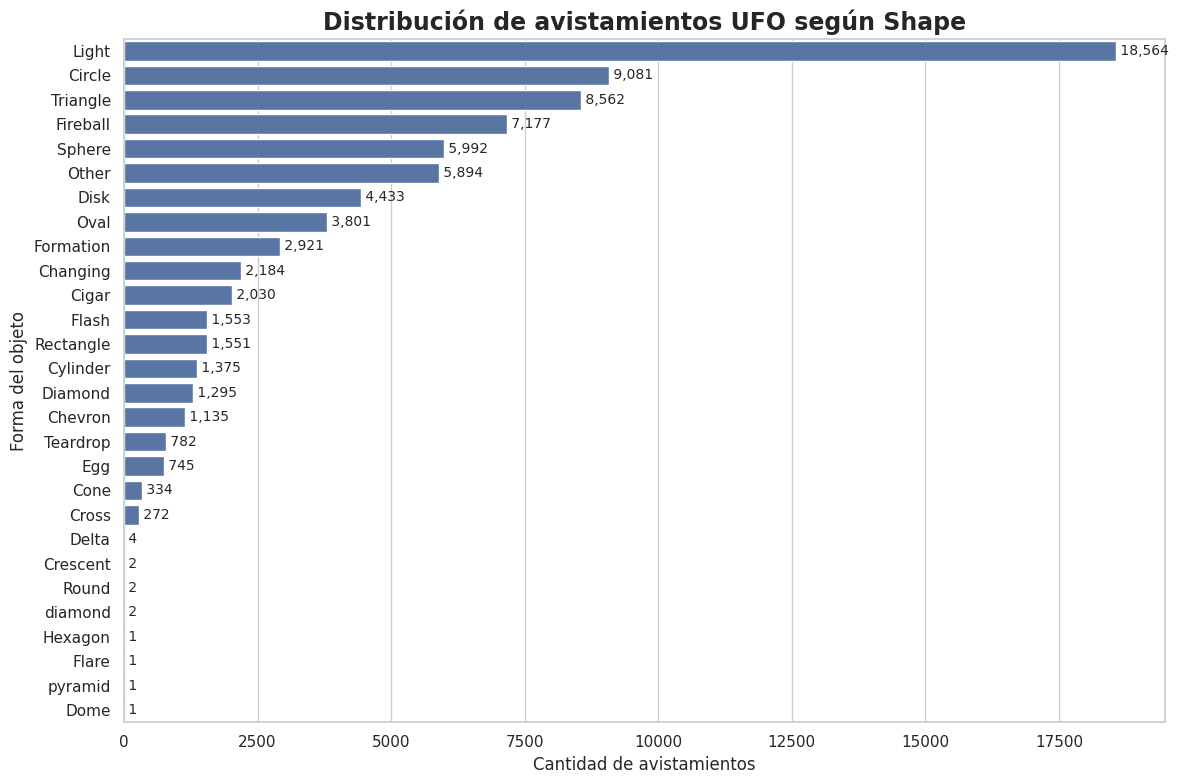

In [4]:
# ============================================
# ANÁLISIS DE LA VARIABLE OBJETIVO: SHAPE
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# --------------------------------------------
# Información general
# --------------------------------------------

print("========== VARIABLE OBJETIVO: SHAPE ==========")

print(f"\nCantidad de variables del dataset: {len(df_procesado.columns)}")
print(f"Cantidad de clases de Shape: {df_procesado['shape'].nunique()}")

print("\nFormas de OVNI registradas:")
print(df_procesado["shape"].dropna().unique())

# --------------------------------------------
# Frecuencia de cada clase
# --------------------------------------------

frecuencias = (
    df_procesado["shape"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de frecuencia de registros por forma:")
display(frecuencias.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn
# --------------------------------------------

plt.figure(figsize=(12, 8))

sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index
)

plt.title(
    "Distribución de avistamientos UFO según Shape",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Cantidad de avistamientos")
plt.ylabel("Forma del objeto")

# Mostrar valores
for i, valor in enumerate(frecuencias.values):
    plt.text(
        valor,
        i,
        f" {valor:,}",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

2.2 ANÁLISIS DE LA COLUMNA shape_grouped (FORMAS DE OVNIS AGRUPADAS)

========== VARIABLE: SHAPE_GROUPED ==========

Cantidad de variables del dataset: 25
Cantidad de clases de Shape Grouped: 7

Formas agrupadas de OVNI registradas:
['Other' 'Triangle' 'Circle' 'Light' 'Sphere' 'Fireball' 'Disk']

Cantidad de frecuencia de registros por forma agrupada:


,Cantidad de registros
shape_grouped,
Other,25886
Light,18564
Circle,9081
Triangle,8562
Fireball,7177
Sphere,5992
Disk,4433


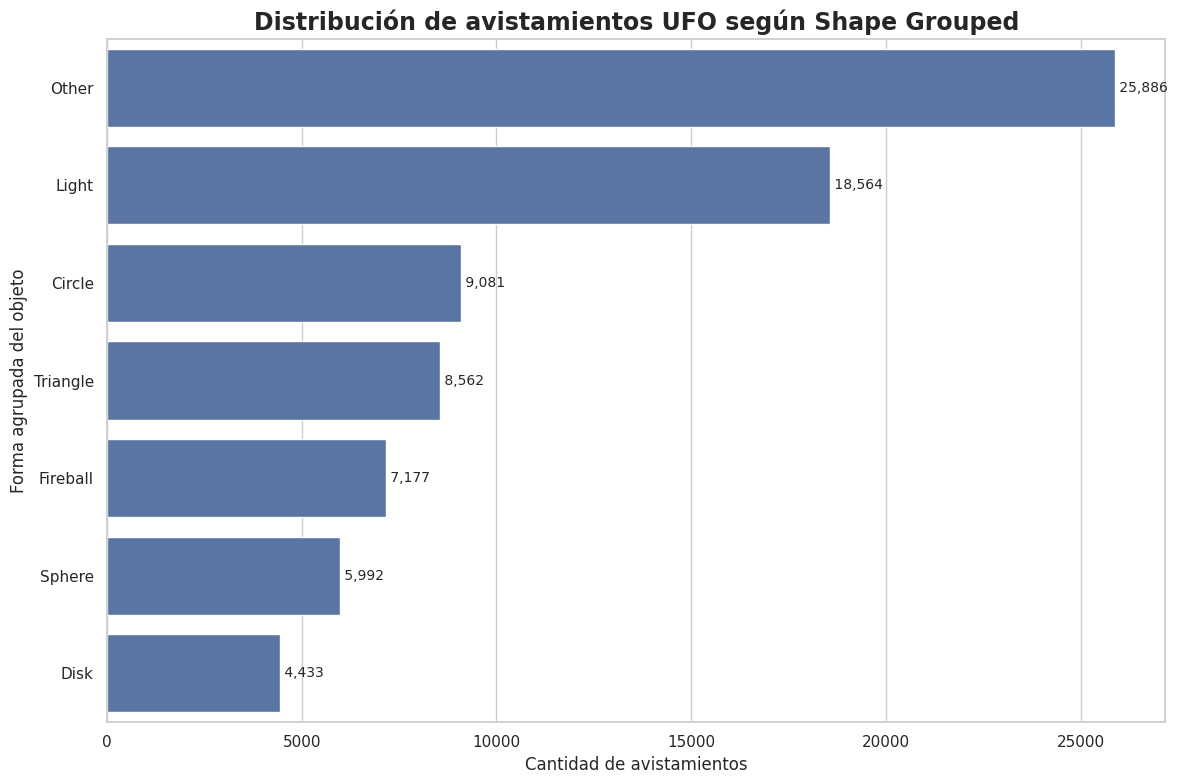

In [5]:
# ============================================
# ANÁLISIS DE LA VARIABLE: SHAPE_GROUPED
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# --------------------------------------------
# Información general
# --------------------------------------------

print("========== VARIABLE: SHAPE_GROUPED ==========")

print(f"\nCantidad de variables del dataset: {len(df_procesado.columns)}")
print(f"Cantidad de clases de Shape Grouped: {df_procesado['shape_grouped'].nunique()}")

print("\nFormas agrupadas de OVNI registradas:")
print(df_procesado["shape_grouped"].dropna().unique())

# --------------------------------------------
# Frecuencia de cada clase
# --------------------------------------------

frecuencias_grouped = (
    df_procesado["shape_grouped"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de frecuencia de registros por forma agrupada:")
display(frecuencias_grouped.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn
# --------------------------------------------

plt.figure(figsize=(12, 8))

sns.barplot(
    x=frecuencias_grouped.values,
    y=frecuencias_grouped.index
)

plt.title(
    "Distribución de avistamientos UFO según Shape Grouped",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Cantidad de avistamientos")
plt.ylabel("Forma agrupada del objeto")

# Mostrar valores
for i, valor in enumerate(frecuencias_grouped.values):
    plt.text(
        valor,
        i,
        f" {valor:,}",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

## 3. Consulta de las dimensiones del DataFrame Limpio

In [6]:
# Consultar las dimensiones del DataFrame
print(f"\n--- Dimensiones del DataFrame (.shape) ---")
print(f"Total de filas: {df_procesado.shape[0]:,}")
print(f"Total de columnas: {df_procesado.shape[1]:,}")



--- Dimensiones del DataFrame (.shape) ---
Total de filas: 79,695
Total de columnas: 25


## 4. Revisión de nombres y tipos de columnas.

In [7]:
# Revisión completa de nombres, tipos de datos y valores nulos
print("\n--- Información general del DataFrame (.info()) ---")
df_procesado.info()

# Si solo quieres ver la lista de los nombres de las columnas:
print("\n--- Nombres de las columnas (.columns) ---")
print(list(df_procesado.columns))



--- Información general del DataFrame (.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79695 entries, 0 to 79694
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   occurred_date_time      79695 non-null  object
 1   city                    79630 non-null  object
 2   state                   79695 non-null  object
 3   shape                   79695 non-null  object
 4   duration                79695 non-null  object
 5   posted_date             79695 non-null  object
 6   year                    79695 non-null  int64 
 7   state_grouped           79695 non-null  object
 8   duration_seconds        79695 non-null  int64 
 9   occurred_datetime       79695 non-null  object
 10  month                   79695 non-null  int64 
 11  month_category          79695 non-null  object
 12  north_season            79695 non-null  object
 13  day_of_week             79695 non-null  int64 
 14  d

## 5. Obtención de estadísticas descriptivas.

In [8]:
# Estadísticas descriptivas básicas para columnas numéricas
print("\n--- Estadísticas de columnas numéricas (.describe()) ---")
display(df_procesado.describe())

# Estadísticas descriptivas incluyendo columnas de texto (categóricas)
print("\n--- Estadísticas incluyendo columnas categóricas (.describe(include='all')) ---")
display(df_procesado.describe(include='all'))

# OTRO

print("\n========== RESUMEN ESTADÍSTICO ==========")
display(df_procesado.describe(include="all").T)


--- Estadísticas de columnas numéricas (.describe()) ---


,year,duration_seconds,month,day_of_week,hour,posted_year,posted_month
count,79695.000000,79695.000000,79695.000000,79695.000000,79695.000000,79695.000000,79695.000000
mean,2008.503946,739.115829,6.894862,3.195269,15.782370,2009.962419,6.732154
std,7.819345,3566.816652,3.241615,1.976876,7.585528,5.541993,3.428519
min,1962.000000,0.000000,1.000000,0.000000,0.000000,1998.000000,1.000000
25%,2004.000000,30.000000,4.000000,1.000000,11.000000,2006.000000,4.000000
50%,2011.000000,180.000000,7.000000,3.000000,19.000000,2011.000000,7.000000
75%,2014.000000,600.000000,10.000000,5.000000,21.000000,2014.000000,10.000000
max,2019.000000,162000.000000,12.000000,6.000000,23.000000,2019.000000,12.000000



--- Estadísticas incluyendo columnas categóricas (.describe(include='all')) ---


,occurred_date_time,city,state,shape,duration,posted_date,year,state_grouped,duration_seconds,occurred_datetime,...,Duracion_clasificacion,hour,time_of_day,is_weekend,shape_grouped,decade,us_region,posted_year,posted_month,posted_dayofweek
count,79695,79630,79695,79695,79695,79695,79695.000000,79695,79695.000000,79695,...,79695,79695.000000,79695,79695,79695,79695,79695,79695.000000,79695.000000,79695
unique,69764,15854,52,28,6885,565,NaN,10,NaN,69665,...,4,NaN,4,2,7,6,4,NaN,NaN,7
top,11/7/15 18:00,Phoenix,CA,Light,5 minutes,2009-12-12,NaN,Other,NaN,2015-11-07 18:00:00,...,Muy corto,NaN,Noche,Día de semana,Other,2010s,West,NaN,NaN,Friday
freq,83,521,10558,18564,5829,1088,NaN,40768,NaN,83,...,29793,NaN,45800,53324,25886,43438,27637,NaN,NaN,19644
mean,NaN,NaN,NaN,NaN,NaN,NaN,2008.503946,NaN,739.115829,NaN,...,NaN,15.782370,NaN,NaN,NaN,NaN,NaN,2009.962419,6.732154,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,7.819345,NaN,3566.816652,NaN,...,NaN,7.585528,NaN,NaN,NaN,NaN,NaN,5.541993,3.428519,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1962.000000,NaN,0.000000,NaN,...,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,1998.000000,1.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2004.000000,NaN,30.000000,NaN,...,NaN,11.000000,NaN,NaN,NaN,NaN,NaN,2006.000000,4.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2011.000000,NaN,180.000000,NaN,...,NaN,19.000000,NaN,NaN,NaN,NaN,NaN,2011.000000,7.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2014.000000,NaN,600.000000,NaN,...,NaN,21.000000,NaN,NaN,NaN,NaN,NaN,2014.000000,10.000000,NaN



========== RESUMEN ESTADÍSTICO ==========


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
occurred_date_time,79695,69764,11/7/15 18:00,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,79630,15854,Phoenix,521,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,79695,52,CA,10558,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shape,79695,28,Light,18564,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,79695,6885,5 minutes,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
posted_date,79695,565,2009-12-12,1088,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,79695.0,NaN,NaN,NaN,2008.503946,7.819345,1962.0,2004.0,2011.0,2014.0,2019.0
state_grouped,79695,10,Other,40768,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_seconds,79695.0,NaN,NaN,NaN,739.115829,3566.816652,0.0,30.0,180.0,600.0,162000.0
occurred_datetime,79695,69665,2015-11-07 18:00:00,83,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Identificación de valores faltantes y duplicados.

========== INFORMACIÓN DEL DATASET ==========

Cantidad de registros: 79,695
Cantidad de variables: 25

========== NOMBRES DE LAS VARIABLES ==========
1. occurred_date_time
2. city
3. state
4. shape
5. duration
6. posted_date
7. year
8. state_grouped
9. duration_seconds
10. occurred_datetime
11. month
12. month_category
13. north_season
14. day_of_week
15. day_category
16. Duracion_clasificacion
17. hour
18. time_of_day
19. is_weekend
20. shape_grouped
21. decade
22. us_region
23. posted_year
24. posted_month
25. posted_dayofweek

========== TIPOS DE DATOS ==========
occurred_date_time        object
city                      object
state                     object
shape                     object
duration                  object
posted_date               object
year                       int64
state_grouped             object
duration_seconds           int64
occurred_datetime         object
month                      int64
month_category            object
north_season              obje

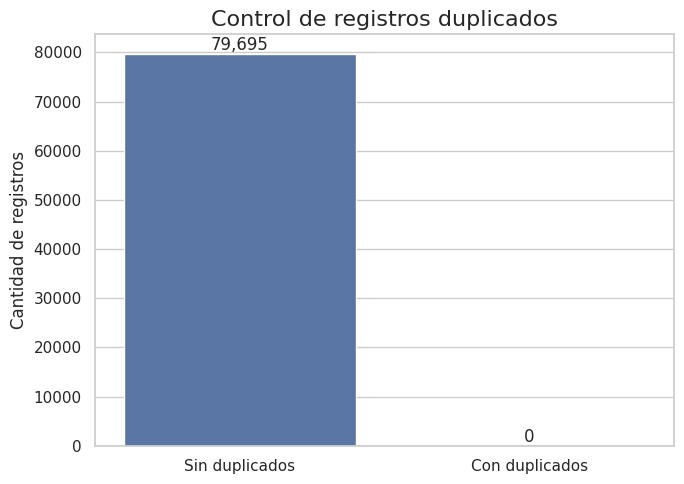

In [9]:
# Exploración inicial del dataset

print("========== INFORMACIÓN DEL DATASET ==========")
print(f"\nCantidad de registros: {df_procesado.shape[0]:,}")
print(f"Cantidad de variables: {df_procesado.shape[1]}")
print("\n========== NOMBRES DE LAS VARIABLES ==========")
for i, columna in enumerate(df_procesado.columns, start=1):
    print(f"{i}. {columna}")

print("\n========== TIPOS DE DATOS ==========")
print(df_procesado.dtypes)

print("\n========== REGISTROS DUPLICADOS ==========")
# Duplicados
duplicados = df_procesado.duplicated().sum()
print("\n🔹 REGISTROS DUPLICADOS")
print(f"   {duplicados:,} registros duplicados")
print("\n" * 2)

duplicados = df_procesado.duplicated().sum()
resultado = pd.DataFrame({
    "Estado": ["Sin duplicados", "Con duplicados"],
    "Cantidad": [
        len(df_procesado) - duplicados,
        duplicados
    ]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=resultado,
    x="Estado",
    y="Cantidad"
)

plt.title("Control de registros duplicados", fontsize=16)
plt.xlabel("")
plt.ylabel("Cantidad de registros")

for i, valor in enumerate(resultado["Cantidad"]):
    plt.text(i, valor, f"{valor:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


VERIFICACIÓN DE VALORES NULOS

In [10]:
import numpy as np
import pandas as pd

# =========================================================
# 1. DIAGNÓSTICO COMPLETO DE VALORES NULOS
# =========================================================


def diagnostico_nulos(df):
    nulos_cant = df.isnull().sum()
    nulos_porc = (df.isnull().mean() * 100).round(2)

    df_diagnostico = pd.DataFrame(
        {"Cantidad_Nulos": nulos_cant, "Porcentaje_Nulos(%)": nulos_porc}
    )

    return df_diagnostico[df_diagnostico["Cantidad_Nulos"] > 0].sort_values(
        by="Porcentaje_Nulos(%)", ascending=False
    )


print("--- DIAGNÓSTICO INICIAL DE NULOS ---")
df_nulos_info = diagnostico_nulos(df_procesado)

if not df_nulos_info.empty:
    display(df_nulos_info.style.background_gradient(cmap="Reds"))
else:
    print("¡El dataset está completamente libre de valores nulos!")


# =========================================================
# 2. ESTRATEGIA DE LIMPIEZA GENERAL
# =========================================================

# A. Opcional: Eliminar columnas que tengan un porcentaje crítico de nulos (ej. mayor al 50%)
umbral_columnas = 0.50
cols_validas = df_procesado.columns[df_procesado.isnull().mean() <= umbral_columnas]
df_procesado = df_procesado[cols_validas]

# B. Imputación para variables NUMÉRICAS (usando la mediana para evitar sesgos por outliers)
cols_num = df_procesado.select_dtypes(include=[np.number]).columns
for col in cols_num:
    if df_procesado[col].isnull().sum() > 0:
        mediana_val = df_procesado[col].median()
        df_procesado[col] = df_procesado[col].fillna(mediana_val)

# C. Imputación para variables CATEGÓRICAS / TEXTO (etiquetando como "Desconocido")
cols_cat = df_procesado.select_dtypes(include=["object", "string"]).columns
for col in cols_cat:
    if df_procesado[col].isnull().sum() > 0:
        df_procesado[col] = df_procesado[col].fillna("Desconocido")

# Esta es la forma definitiva de limpiar y actualizar tu DataFrame principal (corregido df -> df_procesado):
df_procesado['duration_seconds'] = pd.to_numeric(df_procesado['duration_seconds'], errors='coerce')
df_procesado = df_procesado.dropna(subset=['duration_seconds']).copy()

print("Filas totales limpias:", len(df_procesado)) # Aquí ya no debe haber nulos

# D. Limpieza final: Eliminar cualquier fila remanente que aún contenga nulos críticos
df_procesado = df_procesado.dropna().reset_index(drop=True)

print(
    f"\n✅ Limpieza completada. Dimensiones finales del DataFrame: {df_procesado.shape}"
)

--- DIAGNÓSTICO INICIAL DE NULOS ---


,Cantidad_Nulos,Porcentaje_Nulos(%)
city,65,0.080000


Filas totales limpias: 79695

✅ Limpieza completada. Dimensiones finales del DataFrame: (79695, 25)


## 6. Visualizaciones y análisis varios.

**NUEVO ANÁLISIS PARA VER RESULTADOS EN LA VARIABLE OBJETIVO: `shape` (FORMA DEL OBJETO)**

Descartar Light, Other,Unknown,Delta,Crescent,Round,diamond,Hexagon,Flare,Dome,


In [11]:
# Lista de formas que deseas descartar (en minúsculas para abarcar todas las variantes)
formas_a_descartar = [
    "light", "other", "unknown", "delta", "crescent",
    "round", "diamond", "hexagon", "flare", "dome", "pyramid"
]

# Inicializamos df_limpio a partir del DataFrame activo 'df_procesado'
df_limpio = df_procesado.copy()

# Filtrar el DataFrame descartando los registros cuyas formas estén en la lista
# Usamos .str.lower() y .astype(str) para evitar errores con nulos (NaN) o diferencias de mayúsculas
df_limpio = df_limpio[~df_limpio["shape"].astype(str).str.lower().isin(formas_a_descartar)]

print(f"Registros restantes después de filtrar: {df_limpio.shape[0]:,}")

# Verificar cómo quedó el conteo de formas actualizado
print("\n--- Conteo de formas resultante ---")
display(df_limpio["shape"].value_counts())

Registros restantes después de filtrar: 53,928

--- Conteo de formas resultante ---


,count
shape,
Circle,9081
Triangle,8562
Fireball,7177
Sphere,5992
Disk,4433
Oval,3801
Formation,2921
Changing,2184
Cigar,2030


RESULTADO: NUEVA VISUALIZACIÓN DE LA VARIABLE OBJETIVO: `shape` (FORMA DEL OBJETO)

========== VARIABLE OBJETIVO: SHAPE (FILTRADO) ==========

Cantidad de registros originales: 79,695
Cantidad de registros después del filtro: 53,928
Cantidad de clases restantes de Shape: 17

Cantidad de registros por forma (filtrado):


,Cantidad de registros
shape,
Circle,9081
Triangle,8562
Fireball,7177
Sphere,5992
Disk,4433
Oval,3801
Formation,2921
Changing,2184
Cigar,2030


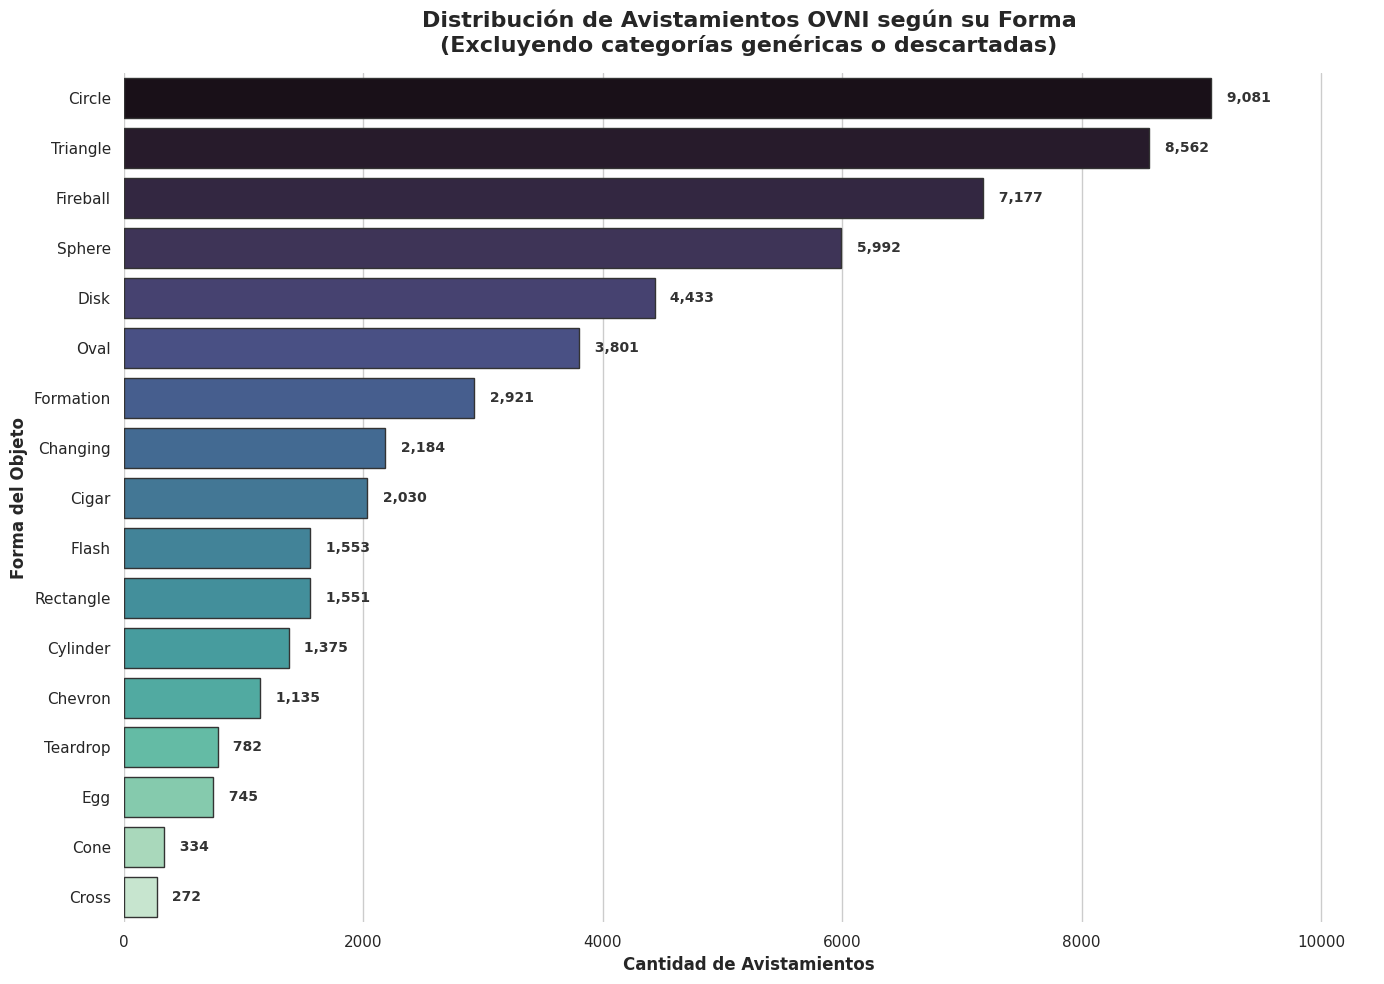

In [12]:
# ============================================
# ANÁLISIS DE LA VARIABLE OBJETIVO: SHAPE (Filtrado)
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de estilo
sns.set_theme(style="whitegrid")

# 1. Definir la lista de formas a descartar (en minúsculas)
descartar = [
    "light", "other", "unknown", "delta", "crescent",
    "round", "diamond", "hexagon", "flare", "dome", "pyramid","2013"
]

# 2. Filtrar el DataFrame excluyendo esas formas (insensible a mayúsculas/minúsculas y espacios)
df_filtrado = df_procesado[~df_procesado["shape"].astype(str).str.lower().str.strip().isin(descartar)].copy()

# --------------------------------------------
# Información general del dataset filtrado
# --------------------------------------------
print("========== VARIABLE OBJETIVO: SHAPE (FILTRADO) ==========")
print(f"\nCantidad de registros originales: {len(df_procesado):,}")
print(f"Cantidad de registros después del filtro: {len(df_filtrado):,}")
print(f"Cantidad de clases restantes de Shape: {df_filtrado['shape'].nunique()}")

# --------------------------------------------
# Frecuencia de cada clase restante
# --------------------------------------------
frecuencias = (
    df_filtrado["shape"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de registros por forma (filtrado):")
display(frecuencias.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn (Más vistoso)
# --------------------------------------------
plt.figure(figsize=(14, 10))

ax = sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index,
    hue=frecuencias.index,
    palette="mako",
    legend=False,
    edgecolor=".2"
)

plt.title(
    "Distribución de Avistamientos OVNI según su Forma\n(Excluyendo categorías genéricas o descartadas)",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Cantidad de Avistamientos", fontsize=12, fontweight="bold")
plt.ylabel("Forma del Objeto", fontsize=12, fontweight="bold")

# Extender ligeramente el eje X para que los números no se corten
plt.xlim(0, frecuencias.values.max() * 1.15)

# Mostrar valores numéricos al lado de cada barra
for i, valor in enumerate(frecuencias.values):
    ax.text(
        valor + (frecuencias.values.max() * 0.01),
        i,
        f" {valor:,}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="semibold",
        color="#333333"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### ANÁLISIS GEOGRÁFICOS

FILTRADO DE ESTADOS DE EE.UU - SE EXCLUYE RESTO DEL MUNDO (OTHER)

In [13]:
import pandas as pd

# 1. Utilizar el dataset cargado en memoria para evitar el FileNotFoundError
df = df_procesado.copy()

# 2. Definir los estados de Estados Unidos
estados_usa = {
    "ALABAMA", "ALASKA", "ARIZONA", "ARKANSAS", "CALIFORNIA",
    "COLORADO", "CONNECTICUT", "DELAWARE", "FLORIDA", "GEORGIA",
    "HAWAII", "IDAHO", "ILLINOIS", "INDIANA", "IOWA", "KANSAS",
    "KENTUCKY", "LOUISIANA", "MAINE", "MARYLAND", "MASSACHUSETTS",
    "MICHIGAN", "MINNESOTA", "MISSISSIPPI", "MISSOURI", "MONTANA",
    "NEBRASKA", "NEVADA", "NEW HAMPSHIRE", "NEW JERSEY",
    "NEW MEXICO", "NEW YORK", "NORTH CAROLINA", "NORTH DAKOTA",
    "OHIO", "OKLAHOMA", "OREGON", "PENNSYLVANIA", "RHODE ISLAND",
    "SOUTH CAROLINA", "SOUTH DAKOTA", "TENNESSEE", "TEXAS", "UTAH",
    "VERMONT", "VIRGINIA", "WASHINGTON", "WEST VIRGINIA",
    "WISCONSIN", "WYOMING", "DISTRICT OF COLUMBIA"
}

abreviaturas_usa = {
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "DC"
}

# 3. Normalizar los valores de state
state_normalizado = (
    df["state"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# 4. Seleccionar los registros de Estados Unidos
mascara_usa = (
    state_normalizado.isin(estados_usa)
    | state_normalizado.isin(abreviaturas_usa)
)

df_usa = df.loc[mascara_usa].copy()

# 5. Mostrar la cantidad de registros seleccionados
print("Total de registros originales:", len(df))
print("Registros seleccionados de Estados Unidos:", len(df_usa))
print("Registros excluidos:", len(df) - len(df_usa))

# 6. Analizar la distribución de shape
distribucion_shape = (
    df_usa["shape"]
    .value_counts(dropna=False)
    .rename_axis("Categoría_shape")
    .reset_index(name="Cantidad")
)

# 7. Calcular el porcentaje de cada categoría
distribucion_shape["Porcentaje"] = (
    distribucion_shape["Cantidad"] / len(df_usa) * 100
).round(2)

# 8. Identificar categorías minoritarias
distribucion_shape["Categoria_minoritaria"] = (
    distribucion_shape["Cantidad"] < 30
)

# 9. Mostrar resultados
print("\nDistribución de las categorías de shape:")
print(distribucion_shape.to_string(index=False))

# 10. Guardar los resultados para documentar el análisis
distribucion_shape.to_csv(
    "distribucion_shape_usa.csv",
    index=False,
    encoding="utf-8-sig"
)

# 11. Guardar el dataset filtrado
df_usa.to_csv(
    "dataset_usa.csv",
    index=False,
    encoding="utf-8-sig"
)

Total de registros originales: 79695
Registros seleccionados de Estados Unidos: 79695
Registros excluidos: 0

Distribución de las categorías de shape:
Categoría_shape  Cantidad  Porcentaje  Categoria_minoritaria
          Light     18564       23.29                  False
         Circle      9081       11.39                  False
       Triangle      8562       10.74                  False
       Fireball      7177        9.01                  False
         Sphere      5992        7.52                  False
          Other      5894        7.40                  False
           Disk      4433        5.56                  False
           Oval      3801        4.77                  False
      Formation      2921        3.67                  False
       Changing      2184        2.74                  False
          Cigar      2030        2.55                  False
          Flash      1553        1.95                  False
      Rectangle      1551        1.95                  F

### FRECUENCIAS DE AVISTAMIENTOS POR ESTADO EN EE.UU

El gráfico incluye 51 barras: los 50 estados más DC, que es el Distrito de Columbia (donde está Washington D. C.), que no es un estado sino un distrito federal. No se confunda WA (el estado de Washington, en la costa oeste) con DC (la capital del país).

California lidera con 10.559 avistamientos, seguida de Florida (5.102) y Washington (4.295). Hay que tener en cuenta que los estados más poblados suelen tener más reportes simplemente por tener más gente, así que este gráfico no necesariamente indica que haya más actividad “real” en esos lugares.

========== FRECUENCIAS DE AVISTAMIENTOS POR ESTADO (DE MAYOR A MENOR) ==========


,Cantidad de Avistamientos
state,
CA,10559
FL,5102
WA,4295
TX,3664
NY,3583
AZ,3193
PA,3004
IL,2800
OH,2729


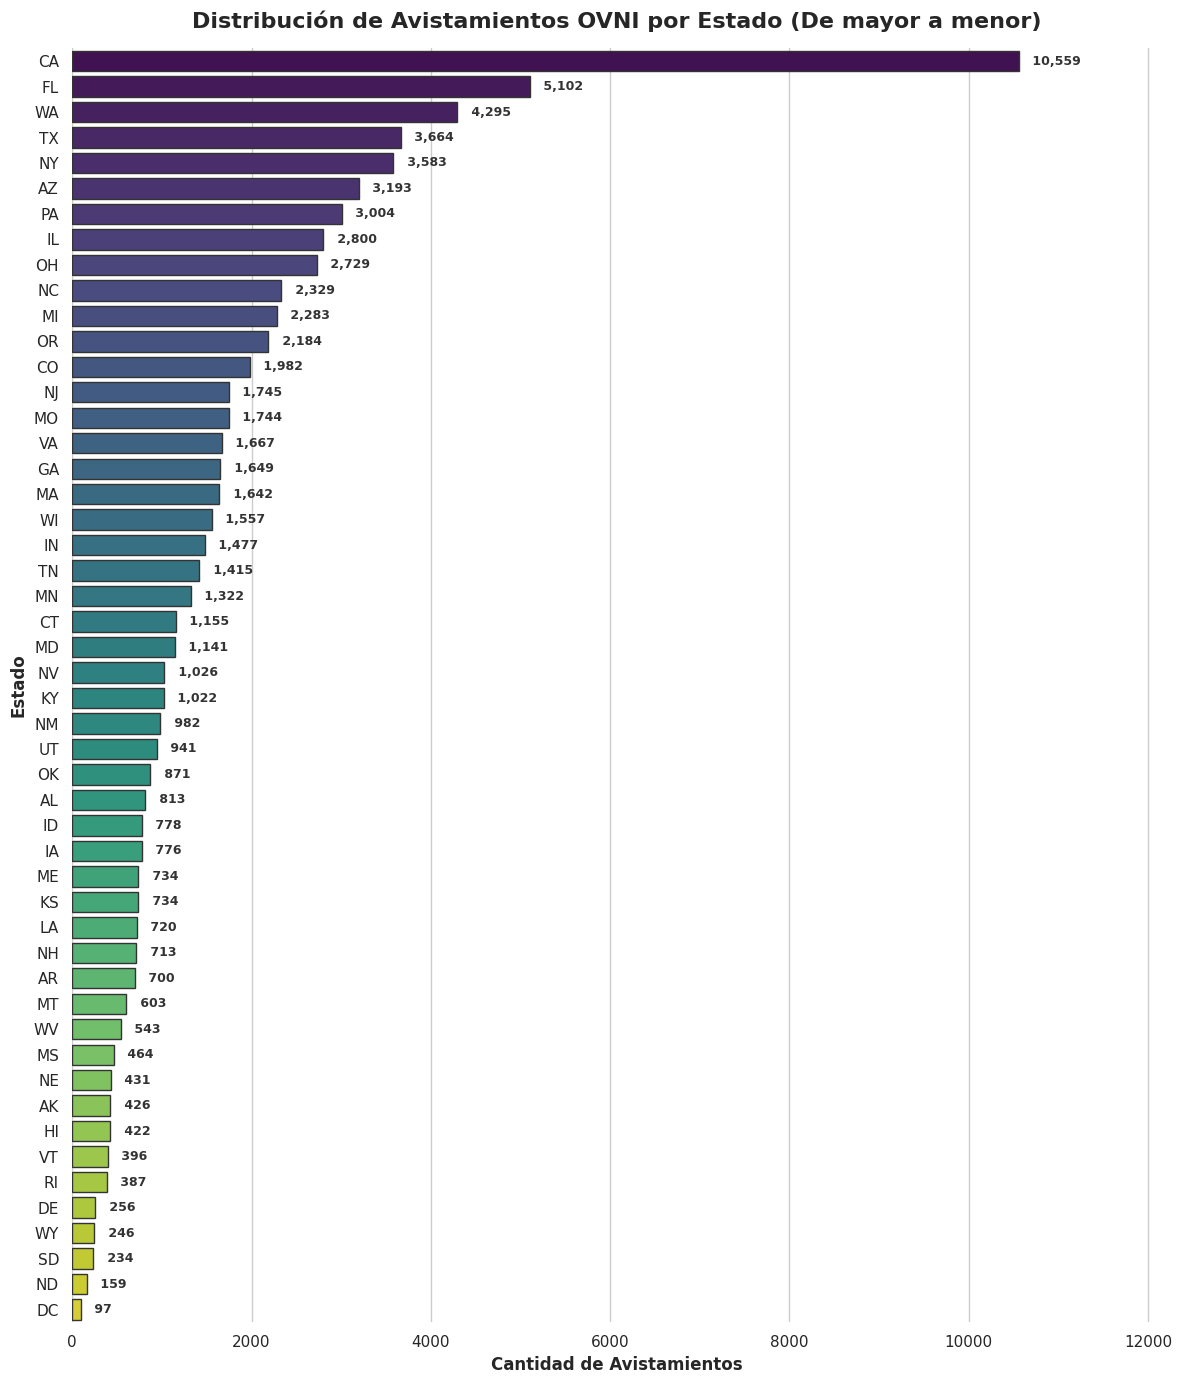

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración general de estilo
sns.set_theme(style="whitegrid")

# 1. Calcular frecuencias de la columna 'state' ordenadas de mayor a menor (descendente)
frecuencias_state = (
    df_usa["state"]
    .astype(str)
    .str.strip()
    .str.upper()
    .value_counts()
    .sort_values(ascending=False)  # Mayor a menor (el mayor arriba)
)

print("========== FRECUENCIAS DE AVISTAMIENTOS POR ESTADO (DE MAYOR A MENOR) ==========")
display(frecuencias_state.to_frame("Cantidad de Avistamientos"))

# 2. Gráfico de barras horizontales (orden descendente)
plt.figure(figsize=(12, 14))

ax = sns.barplot(
    x=frecuencias_state.values,
    y=frecuencias_state.index,
    hue=frecuencias_state.index,
    palette="viridis",
    legend=False,
    edgecolor=".2"
)

plt.title(
    "Distribución de Avistamientos OVNI por Estado (De mayor a menor)",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Cantidad de Avistamientos", fontsize=12, fontweight="bold")
plt.ylabel("Estado", fontsize=12, fontweight="bold")

# Extender ligeramente el eje X para que los números no se corten
plt.xlim(0, frecuencias_state.values.max() * 1.15)

# Mostrar valores numéricos al lado de cada barra
for i, valor in enumerate(frecuencias_state.values):
    ax.text(
        valor + (frecuencias_state.values.max() * 0.01),
        i,
        f" {valor:,}",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="semibold",
        color="#333333"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

### ANÁLISIS TEMPORAL DE LOS AVISTAMIENTOS UFO - OVNIS

AVISTAMIENTOS EN CADA DÍA DE LA SEMANA - CONTEO

In [15]:
print('Nota: `is_weekend` clasifica el VIERNES como fin de semana (ver crosstab más abajo).')
display(pd.crosstab(df['day_category'], df['is_weekend']).reindex(['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo']))


Nota: `is_weekend` clasifica el VIERNES como fin de semana (ver crosstab más abajo).


is_weekend,Día de semana,Fin de semana
day_category,,
Lunes,9712,0
Martes,10338,0
Miércoles,10675,0
Jueves,10857,0
Viernes,11742,0
Sábado,0,14806
Domingo,0,11565


AGRUPACIONES VARIOS

In [16]:
df['occurred_datetime'] = pd.to_datetime(df['occurred_datetime'])
df['posted_date'] = pd.to_datetime(df['posted_date'])

orden_meses = ['Enero','Febrero','Marzo','Abril','Mayo','Junio','Julio','Agosto','Septiembre','Octubre','Noviembre','Diciembre']
orden_dias = ['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo']
orden_tod = ['Madrugada','Mañana','Tarde','Noche']
orden_dur = ['Muy corto','Corto','Medio','Largo']

cat_cols = ['state_grouped','shape_grouped','month_category','north_season','day_category','Duracion_clasificacion',
            'time_of_day','is_weekend','decade','us_region']
df[cat_cols].nunique().to_frame('categorías')

,categorías
state_grouped,10
shape_grouped,7
month_category,12
north_season,4
day_category,7
Duracion_clasificacion,4
time_of_day,4
is_weekend,2
decade,6
us_region,4



CLASIFICACIÓN DE DURACIÓN EN LA COLUMNA: Duracion_clasificacion
---

###Transformación de la duración del avistamiento en categorías

La variable `duration_seconds` representa la duración de un avistamiento OVNI expresada en segundos. Se aplica la técnica de transformación denominada **categorización o *binning***, que consiste en agrupar los valores numéricos continuos en intervalos definidos. Esta transformación permite analizar la duración mediante categorías temporales y explorar patrones que podrían resultar útiles para comprender el comportamiento de los registros.

###Criterio de categorización - según la fuente: https://canadianuforeport.ca/

The Canadian UFO Survey es un sitio NO oficial donde categoriza las duraciones de los avistamientos.

Los intervalos deben definirse según la distribución real de los datos y los objetivos del análisis. Por ejemplo, se pueden considerar categorías como:

- 🟢 **Muy corto:** hasta 10 segundos.
- 🔵 **Corto:** más de 10 y hasta 60 segundos.
- 🟡 **Medio:** más de 60 y hasta 300 segundos.
- 🟠 **Largo:** más de 300 y hasta 1.800 segundos.
- 🔴 **Muy largo:** más de 1.800 segundos.

*Estos intervalos son una propuesta inicial y deben validarse con la distribución del dataset.*

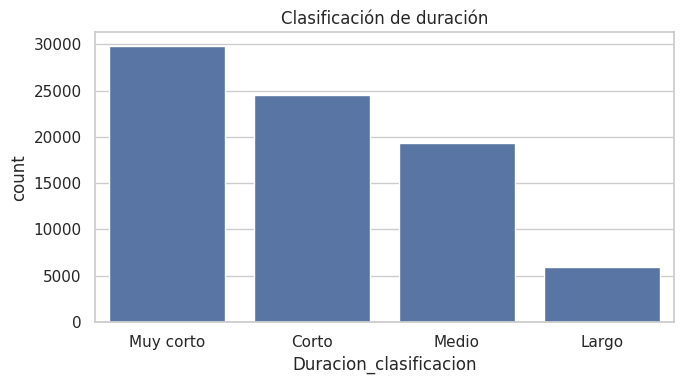

,count,min,median,max
Duracion_clasificacion,,,,
Muy corto,29793,0,15.0,162000
Corto,24546,0,180.0,72000
Medio,19366,0,900.0,108000
Largo,5990,10,3600.0,162000


In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x='Duracion_clasificacion', order=orden_dur, ax=ax)
ax.set_title('Clasificación de duración')
plt.tight_layout()
plt.show()

(df.groupby('Duracion_clasificacion')['duration_seconds'].agg(['count','min','median','max'])
   .reindex(orden_dur))

### VISUALIZACIÓN GENERAL DE AVISTAMIENTOS POR AÑO EN EE.UU.

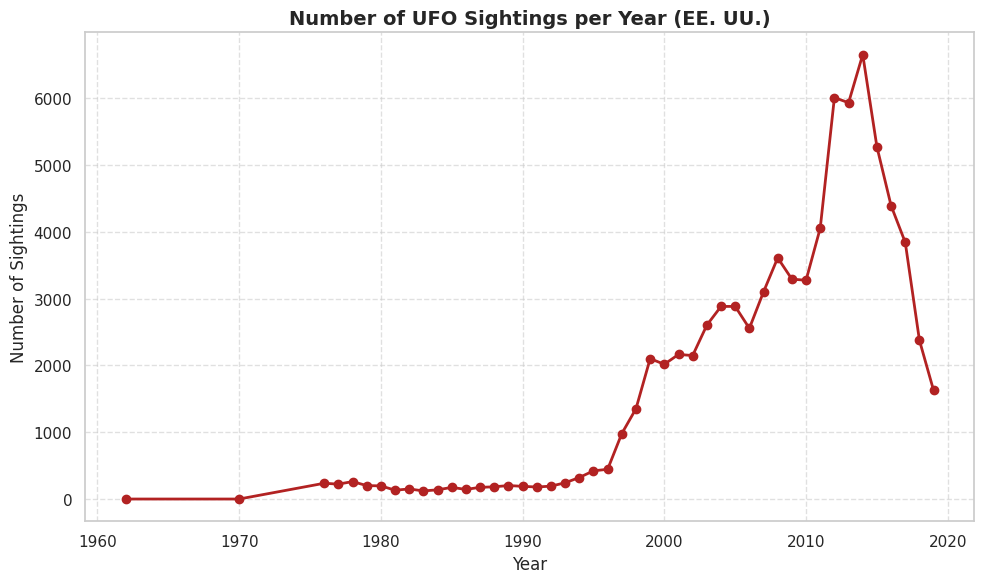

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Agrupar y ordenar por año usando el dataset filtrado (df_usa)
df_year = df_usa["year"].value_counts().reset_index()
df_year.columns = ["year", "sightings"]
df_year = df_year.sort_values("year")

# 2. Configurar y generar la visualización
plt.figure(figsize=(10, 6))
plt.plot(df_year["year"], df_year["sightings"], color="firebrick", marker="o", linewidth=2)

plt.title("Number of UFO Sightings per Year (EE. UU.)", fontsize=14, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Sightings", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()


VISUALIZACIÓN GENERAL DE AVISTAMIENTOS POR DÉCADA Y POR MES

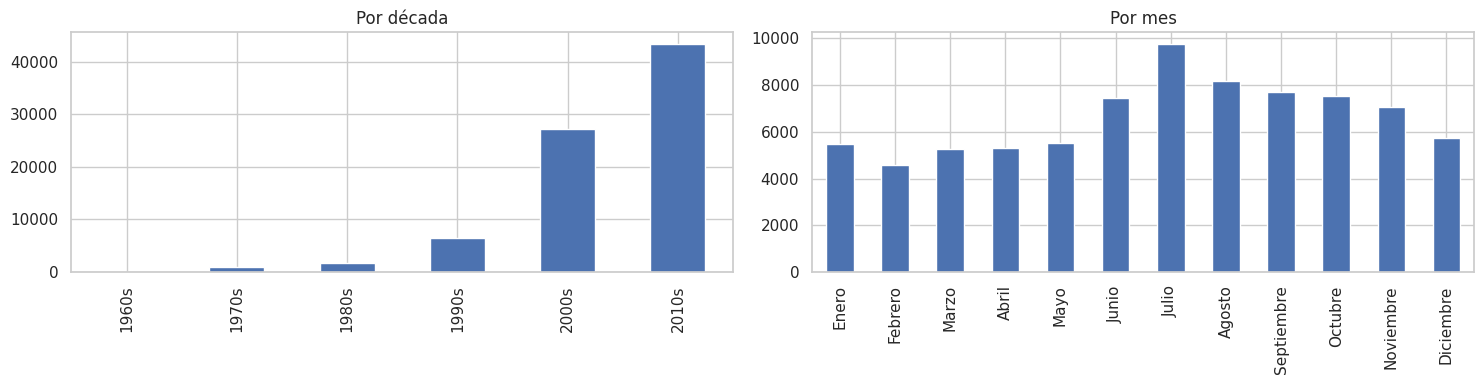

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
df['decade'].value_counts().sort_index().plot.bar(ax=ax[0], title='Por década'); ax[0].set_xlabel('')
df['month_category'].value_counts().reindex(orden_meses).plot.bar(ax=ax[1], title='Por mes'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

VISUALIZACIÓN GENERAL DE AVISTAMIENTOS POR DIA DE LA SEMANA , SEGÚN LA HORA DEL DÍA , SEGÚN EL MOMENTO DEL DÍA QUE TRANSCURRIERON LOS EVENTOS

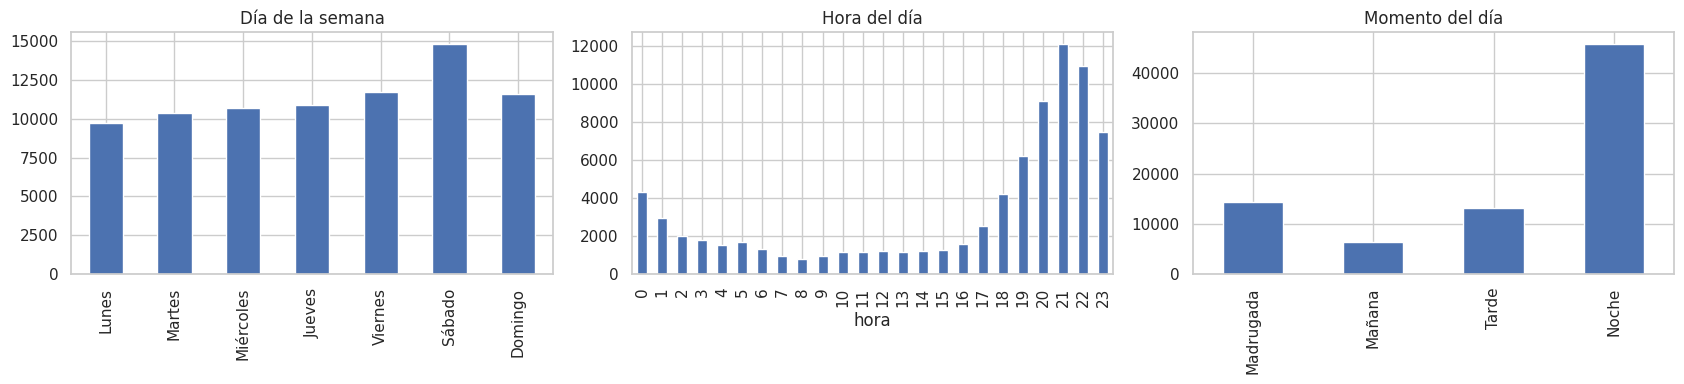

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df['day_category'].value_counts().reindex(orden_dias).plot.bar(ax=ax[0], title='Día de la semana'); ax[0].set_xlabel('')
df.groupby('hour').size().plot.bar(ax=ax[1], title='Hora del día'); ax[1].set_xlabel('hora')
df['time_of_day'].value_counts().reindex(orden_tod).plot.bar(ax=ax[2], title='Momento del día'); ax[2].set_xlabel('')
plt.tight_layout(); plt.show()

VISUALIZACIÓN GENERAL CON MAPA DE CALOR DE LOS AVISTAMIENTOS POR DIA DE LA SEMANA Y SEGÚN LA HORA DEL DÍA

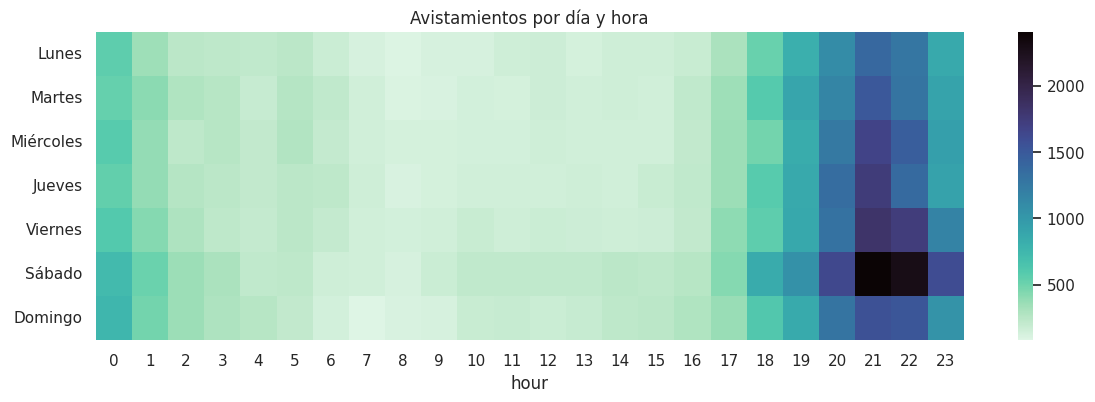

In [21]:
heat = df.pivot_table(index='day_category', columns='hour', values='year', aggfunc='size').reindex(orden_dias)
plt.figure(figsize=(14, 4))
sns.heatmap(heat, cmap='mako_r'); plt.title('Avistamientos por día y hora'); plt.ylabel(''); plt.show()

VISUALIZACIÓN GENERAL DE AVISTAMIENTOS POR ESTACIÓN ANUAL Y SEGÚN SI ES DIA HÁBIL FIN DE SEMANA


#CREACIÓN Y CLASIFICACIÓN DE LOS MESES SEGÚN LAS CUATRO ESTACIONES DEL AÑO (hemisferio norte)

A partir de la fecha de cada avistamiento, se identifica el mes de observación y se lo clasifica en una de las cuatro estaciones: verano, otoño, invierno o primavera.

Esta transformación permite incorporar información estacional al dataset y explorar posibles relaciones entre la época del año y las características de los avistamientos UFO - OVNI.

### Criterio de clasificación — Hemisferio norte

| ☀️ Verano (*Summer*) | Junio, julio y agosto |
| 🍂 Otoño (*Autumn/Fall*) | Septiembre, octubre y noviembre |
| ❄️ Invierno (*Winter*) | Diciembre, enero y febrero |
| 🌸 Primavera (*Spring*) | Marzo, abril y mayo |

### Procedimiento: Guardar el resultado en la nueva columna `season`.

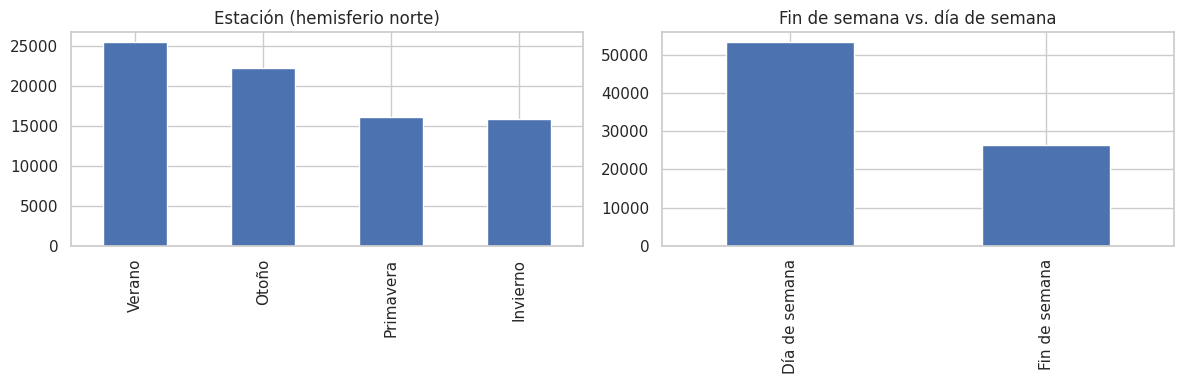

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['north_season'].value_counts().plot.bar(ax=ax[0], title='Estación (hemisferio norte)'); ax[0].set_xlabel('')
df['is_weekend'].value_counts().plot.bar(ax=ax[1], title='Fin de semana vs. día de semana'); ax[1].set_xlabel('')
plt.tight_layout(); plt.show()

In [23]:
# Consultar las dimensiones del DataFrame
print(f"\n--- Dimensiones del DataFrame (.shape) ---")
print(f"Total de filas: {df_procesado.shape[0]:,}")
print(f"Total de columnas: {df_procesado.shape[1]:,}")


--- Dimensiones del DataFrame (.shape) ---
Total de filas: 79,695
Total de columnas: 25
